# Uma primeira investigação com o FD001: remoção por idade vs. regra baseada em T50

| | |
|---|---|
| **Disciplina** | TE-292 — Ciência de Dados em Operação e Manutenção de Aeronaves |
| **Instituição** | Instituto Tecnológico de Aeronáutica (ITA) — AeroLogLab |
| **Professor** | Antonio Celio Pereira de Mesquita |
| **Aluno** | João Oliveira |
| **Atividade** | Aula 7 — C-MAPSS e decisão de manutenção (individual) |

**Pergunta**: uma regra baseada em sensores aproveita melhor a vida do motor do que uma remoção
por idade?

**Protocolo** (seguido à risca do enunciado `tarefa_fd001.md`):

1. `train_FD001.txt`, 100 motores rodando até a falha. Sorteio com semente 42: **70 motores
   para desenvolvimento** e **30 reservados**; todos os ciclos de um motor ficam no mesmo grupo.
2. **Referência por idade**: `a` = menor vida observada nos 70 motores; aviso em `a − 20` e
   remoção em `a`.
3. **Regra com sensor (T50, sensor 4)**: linha de base = média dos ciclos 1–15; a partir do
   ciclo 16, média móvel das 15 leituras mais recentes; aviso único quando a média móvel supera
   a linha de base em `p`%; remoção 20 ciclos depois. `p` ∈ {0,20%; 0,35%; 0,50%} é escolhido
   **só nos 70 motores** (menor custo por ciclo; empate → menor `p`).
4. As duas regras, já fixadas, são aplicadas **uma única vez** aos 30 motores reservados.

O ciclo de falha `T` (último ciclo do motor) é usado **apenas para conferir o desfecho**; o
aviso depende só das leituras até o ciclo atual.

## 0. Contexto: o que os materiais da aula acrescentam

**O que o T50 mede.** O sensor 4 é a temperatura total na **saída da turbina de baixa pressão
(LPT)**, em graus Rankine (°R). Valores em torno de 1 400 °R correspondem a cerca de 505 °C
(Saxena et al., 2008, tabela 2, p. 3; mapa de sensores de Bassani, 2026). No FD001, o desgaste
afeta o compressor de alta pressão (HPC). Para manter o empuxo com um compressor menos eficiente,
o motor trabalha mais quente, e o T50 sobe lentamente ao longo da vida.

**De onde vem a regra.** A regra sugerida é a mesma usada por Bassani (2026, slide 16) para
detectar o **ponto P** em T50: linha de base de 15 ciclos, média móvel de 15 ciclos e limites
relativos de ±0,5%. Como o T50 só sobe com a degradação, usamos apenas o limite superior.

**Como ler a decisão: a curva P–F** (Mesquita, aula 7, slide 18). O aviso marca o ponto P
detectado e a falha `T` marca o ponto F. A remoção chega a tempo **se e somente se o intervalo
P–F (`T − aviso`) for de pelo menos `L` = 20 ciclos**. Um limite baixo detecta cedo, com P–F
longo e muita vida desperdiçada. Um limite alto detecta tarde, com P–F curto e risco de
planejamento perdido.

**Por que custo por ciclo** (Mesquita, aula 7, slide 21). Cada remoção inicia um novo ciclo de
vida instalada. Pelo teorema da renovação com recompensa, o custo de longo prazo por ciclo voado
é `g = E[C]/E[U]`, estimado por `ΣC/ΣU`. Com receita por ciclo fixa, minimizar `g` maximiza o
lucro por ciclo.

**Erros assimétricos** (Saxena et al., 2008, seção VII e figura 10, pp. 7–8). O desafio PHM'08
penaliza mais a previsão tardia que a antecipada. Aqui, essa assimetria aparece na razão
`cf/cp` = 50: um único motor perdido custa o mesmo que 50 remoções planejadas.

## 1. Leitura e divisão dos motores

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

colunas = ["motor", "ciclo"] + [f"ajuste_{i}" for i in range(1, 4)]
colunas += [f"sensor_{i}" for i in range(1, 22)]
dados = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None, names=colunas)
ids = np.random.default_rng(42).permutation(sorted(dados["motor"].unique()))
desenvolvimento = dados[dados["motor"].isin(ids[:70])].copy()
avaliacao = dados[dados["motor"].isin(ids[70:])].copy()

SENSOR = "sensor_4"   # T50: coluna 9 do arquivo (contando a partir de 1)
assert colunas.index(SENSOR) + 1 == 9
assert set(desenvolvimento["motor"]).isdisjoint(avaliacao["motor"])
assert desenvolvimento["motor"].nunique() == 70 and avaliacao["motor"].nunique() == 30
assert len(desenvolvimento) + len(avaliacao) == len(dados)

print(f"linhas: {len(dados)} | valores ausentes: {int(dados.isna().sum().sum())} | motores: {dados['motor'].nunique()}")
print(f"ciclos consecutivos em todos os motores: "
      f"{bool(dados.groupby('motor')['ciclo'].apply(lambda c: (np.diff(c) == 1).all() and c.iloc[0] == 1).all())}")
print("motores reservados para avaliação:", sorted(int(m) for m in ids[70:]))

linhas: 20631 | valores ausentes: 0 | motores: 100
ciclos consecutivos em todos os motores: True
motores reservados para avaliação: [7, 9, 12, 13, 14, 15, 20, 23, 31, 35, 36, 37, 42, 45, 48, 50, 54, 55, 59, 65, 66, 67, 68, 75, 78, 83, 86, 89, 91, 99]


## 2. Parâmetros comuns e simulação do desfecho

| Parâmetro | Valor |
|---|---|
| Tempo logístico `L` | 20 ciclos |
| Custo planejado `cp` | 1 |
| Custo após falha `cf` | 50 |

Convenção: se a remoção programada ocorre até `T` (inclusive), a remoção é **planejada**,
com `U` = ciclo da remoção e `C` = 1. Se a remoção cai depois de `T` ou não há aviso, o
**planejamento é perdido**, com `U` = `T` e `C` = 50.
**Custo por ciclo = ΣC / ΣU.**

In [2]:
L, CP, CF = 20, 1, 50
PERCENTUAIS = [0.0020, 0.0035, 0.0050]
JANELA = 15


def ciclo_de_falha(df: pd.DataFrame) -> pd.Series:
    return df.groupby("motor")["ciclo"].max().rename("T")


def desfecho(avisos: pd.Series, T: pd.Series) -> pd.DataFrame:
    '''Aplica a convenção da simulação. `avisos` tem o ciclo do aviso por motor (NaN = sem aviso).'''
    r = pd.DataFrame({"aviso": avisos, "T": T})
    r["remocao"] = r["aviso"] + L
    r["planejada"] = r["remocao"].notna() & (r["remocao"] <= r["T"])
    r["U"] = np.where(r["planejada"], r["remocao"], r["T"])
    r["C"] = np.where(r["planejada"], CP, CF)
    r["vida_desperdicada"] = np.where(r["planejada"], r["T"] - r["remocao"], np.nan)
    return r


def resumo(r: pd.DataFrame) -> dict:
    planejadas = r["planejada"]
    return {"perdidos": int((~planejadas).sum()),
            "n": len(r),
            "vida_desperdicada_media": r.loc[planejadas, "vida_desperdicada"].mean() if planejadas.any() else np.nan,
            "custo_por_ciclo": r["C"].sum() / r["U"].sum()}

## 3. Referência por idade

A idade de remoção `a` vem **somente** dos 70 motores de desenvolvimento e é a mesma para todos
os motores.

In [3]:
T_dev = ciclo_de_falha(desenvolvimento)
T_aval = ciclo_de_falha(avaliacao)
a = int(T_dev.min())
print(f"idade de remoção a = {a} ciclos (aviso em a − L = {a - L})")
print(f"vida no desenvolvimento: mín {T_dev.min()}, mediana {T_dev.median():.0f}, máx {T_dev.max()}")

idade_dev = desfecho(pd.Series(a - L, index=T_dev.index, dtype=float), T_dev)
print("desenvolvimento:", {k: round(v, 5) if isinstance(v, float) else v for k, v in resumo(idade_dev).items()})

idade de remoção a = 128 ciclos (aviso em a − L = 108)
vida no desenvolvimento: mín 128, mediana 197, máx 362
desenvolvimento: {'perdidos': 0, 'n': 70, 'vida_desperdicada_media': np.float64(77.81429), 'custo_por_ciclo': np.float64(0.00781)}


**A referência é justa?** Na aula (slide 22), com os 100 motores e `cf/cp` ≥ 10, a idade que
minimiza o custo por ciclo é 128 ciclos. Repetimos a varredura **só nos 70 motores de
desenvolvimento**: se a menor vida coincidir com a idade ótima, o enunciado compara o sensor com
a **melhor** política por idade possível, e não com uma referência enfraquecida.

idade ótima nos 70 motores: 128 ciclos | menor vida: 128 -> referência = melhor política por idade: True


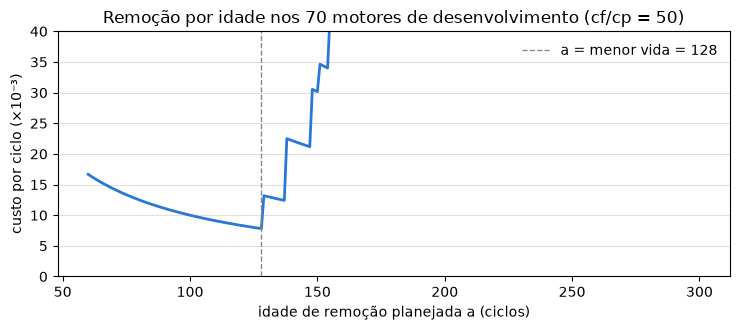

In [4]:
idades = np.arange(60, 301)
custo_idade = [resumo(desfecho(pd.Series(x - L, index=T_dev.index, dtype=float), T_dev))["custo_por_ciclo"]
               for x in idades]
a_otima = int(idades[int(np.argmin(custo_idade))])
print(f"idade ótima nos 70 motores: {a_otima} ciclos | menor vida: {a} -> referência = melhor política por idade: {a_otima == a}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(idades, np.array(custo_idade) * 1e3, color="#2a78d6", linewidth=2)
ax.axvline(a, color="#898781", linestyle="--", linewidth=1, label=f"a = menor vida = {a}")
ax.set_xlabel("idade de remoção planejada a (ciclos)")
ax.set_ylabel("custo por ciclo (×10⁻³)")
ax.set_title("Remoção por idade nos 70 motores de desenvolvimento (cf/cp = 50)")
ax.set_ylim(0, 40)
ax.grid(True, axis="y", color="#e1e0d9")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. Regra baseada em T50

Para cada motor, em ordem de ciclo e usando apenas leituras já observadas:

- **linha de base** = média de T50 nos ciclos 1–15;
- **média móvel** no ciclo `c ≥ 16` = média das leituras `c−14 … c`;
- **aviso** no primeiro ciclo em que média móvel > linha de base × (1 + `p`); remoção em aviso + 20.

In [5]:
def serie_t50(g: pd.DataFrame) -> pd.DataFrame:
    g = g.sort_values("ciclo")
    base = g[SENSOR].iloc[:JANELA].mean()
    media_movel = g[SENSOR].rolling(JANELA).mean()   # janela termina no ciclo atual: só usa o passado
    return pd.DataFrame({"ciclo": g["ciclo"].to_numpy(), "t50": g[SENSOR].to_numpy(),
                         "media_movel": media_movel.to_numpy(), "base": base})


def avisos_sensor(df: pd.DataFrame, p: float) -> pd.Series:
    avisos = {}
    for motor, g in df.groupby("motor"):
        s = serie_t50(g)
        cruzou = (s["ciclo"] >= JANELA + 1) & (s["media_movel"] > s["base"] * (1 + p))
        avisos[motor] = float(s.loc[cruzou, "ciclo"].iloc[0]) if cruzou.any() else np.nan
    return pd.Series(avisos, name="aviso")


selecao = []
for p in PERCENTUAIS:
    linha = resumo(desfecho(avisos_sensor(desenvolvimento, p), T_dev))
    selecao.append({"percentual": f"{p:.2%}", "p": p, **linha})
selecao = pd.DataFrame(selecao)
selecao.loc[len(selecao)] = {"percentual": f"idade (a = {a})", "p": np.nan, **resumo(idade_dev)}

candidatas = selecao.dropna(subset=["p"])
melhor = candidatas.loc[candidatas["custo_por_ciclo"] == candidatas["custo_por_ciclo"].min(), "p"].min()
print(f"percentual escolhido nos 70 motores: {melhor:.2%} (fica fixo na avaliação final)")
selecao.drop(columns="p").style.format({"vida_desperdicada_media": "{:.1f}", "custo_por_ciclo": "{:.5f}"}).hide(axis="index")

percentual escolhido nos 70 motores: 0.35% (fica fixo na avaliação final)


percentual,perdidos,n,vida_desperdicada_media,custo_por_ciclo
0.20%,0,70,100.9,0.00953
0.35%,0,70,68.3,0.00727
0.50%,1,70,43.6,0.01044
idade (a = 128),0,70,77.8,0.00781


**Leitura (desenvolvimento)**: os percentuais mostram o dilema esperado. Com 0,20%, o aviso sai
cedo demais e desperdiça cerca de 100 ciclos por motor. Com 0,50%, o desperdício cai para ~44
ciclos, mas um motor tem o planejamento perdido, e esse único custo de 50 basta para piorar o
custo por ciclo. 0,35% equilibra os dois lados e fica com o menor custo por ciclo, inclusive
abaixo da referência por idade nos mesmos 70 motores.

### O dilema visto pela curva P–F

Para cada percentual, medimos o intervalo P–F (`T − aviso`) nos 70 motores de desenvolvimento.
Os números da aula para a regra relativa de ±0,5% (Mesquita, aula 7, slide 37, com os 100 motores
e vários sensores) servem de comparação: mediana de 54 ciclos, mínimo de 22 e P detectado em 71%
da vida.

In [6]:
pf_rows = []
for p in PERCENTUAIS:
    aviso = avisos_sensor(desenvolvimento, p)
    pf = T_dev - aviso
    pf_rows.append({"percentual": f"{p:.2%}", "P–F mediano": pf.median(), "P–F mínimo": pf.min(),
                    "P em % da vida (mediana)": ((aviso / T_dev) * 100).median(),
                    f"motores com P–F < L = {L}": int((pf < L).sum())})
pd.DataFrame(pf_rows).style.format(precision=0).hide(axis="index")

percentual,P–F mediano,P–F mínimo,P em % da vida (mediana),motores com P–F < L = 20
0.20%,116,55,43,0
0.35%,78,43,60,0
0.50%,57,19,70,1


Com 0,50%, os nossos 70 motores reproduzem o padrão da aula: P–F mediano perto de 55 ciclos,
mínimo abaixo de `L` e detecção a ~70% da vida. Por isso um motor perde o planejamento. Com
0,35%, o P–F mínimo continua bem acima de 20 ciclos, e a regra ganha vida útil sem chegar perto
do limite logístico. Como lembra a aula (slide 38), **antes de refinar a previsão, é preciso
verificar se o critério de detecção deixa janela suficiente para o tempo logístico**.

## 5. Avaliação final nos 30 motores reservados

As duas regras, já fixadas (`a` e `p` escolhidos acima), são aplicadas **uma única vez**.

In [7]:
idade_aval = desfecho(pd.Series(a - L, index=T_aval.index, dtype=float), T_aval)
sensor_aval = desfecho(avisos_sensor(avaliacao, melhor), T_aval)


def linha_tabela(nome, r):
    s = resumo(r)
    return {"Regra": nome,
            "Motores com planejamento perdido / 30": f"{s['perdidos']} / {s['n']}",
            "Vida desperdiçada média, só nas remoções planejadas":
                "não se aplica" if np.isnan(s["vida_desperdicada_media"]) else f"{s['vida_desperdicada_media']:.1f} ciclos",
            "Custo por ciclo": f"{s['custo_por_ciclo']:.5f}"}


comparacao = pd.DataFrame([linha_tabela(f"Remoção por idade (a = {a})", idade_aval),
                           linha_tabela(f"Regra baseada em sensores (T50, +{melhor:.2%})", sensor_aval)])
comparacao.style.hide(axis="index")

Regra,Motores com planejamento perdido / 30,"Vida desperdiçada média, só nas remoções planejadas",Custo por ciclo
Remoção por idade (a = 128),0 / 30,79.5 ciclos,0.00781
"Regra baseada em sensores (T50, +0.35%)",0 / 30,71.7 ciclos,0.00737


In [8]:
cpc_idade, cpc_sensor = resumo(idade_aval)["custo_por_ciclo"], resumo(sensor_aval)["custo_por_ciclo"]
print(f"redução do custo por ciclo: {1 - cpc_sensor / cpc_idade:.1%}")
print(f"ciclos aproveitados por motor (média): idade {idade_aval['U'].mean():.1f} | sensor {sensor_aval['U'].mean():.1f}")
print(f"motores em que o sensor remove mais tarde que a idade: {(sensor_aval['remocao'] > idade_aval['remocao']).sum()} / 30")
print(f"menor folga entre remoção e falha com o sensor: {sensor_aval['vida_desperdicada'].min():.0f} ciclos "
      f"(motor {int(sensor_aval['vida_desperdicada'].idxmin())})")
r_rem = np.corrcoef(sensor_aval["remocao"], T_aval)[0, 1]
print(f"correlação entre ciclo de remoção pelo sensor e vida T: r = {r_rem:.2f} (r² = {r_rem**2:.2f})")
print(f"desvio-padrão da folga T − remoção: idade {idade_aval['vida_desperdicada'].std():.1f} | "
      f"sensor {sensor_aval['vida_desperdicada'].std():.1f} ciclos")

detalhe = pd.DataFrame({
    "T": T_aval,
    "aviso_idade": idade_aval["aviso"].astype(int), "remocao_idade": idade_aval["remocao"].astype(int),
    "aviso_sensor": sensor_aval["aviso"].astype("Int64"), "remocao_sensor": sensor_aval["remocao"].astype("Int64"),
    "desfecho_sensor": np.where(sensor_aval["planejada"], "planejada", "perdida"),
    "folga_sensor": sensor_aval["vida_desperdicada"].astype("Int64"),
}).rename_axis("motor")
detalhe

redução do custo por ciclo: 5.7%
ciclos aproveitados por motor (média): idade 128.0 | sensor 135.8
motores em que o sensor remove mais tarde que a idade: 17 / 30
menor folga entre remoção e falha com o sensor: 28 ciclos (motor 65)
correlação entre ciclo de remoção pelo sensor e vida T: r = 0.58 (r² = 0.34)
desvio-padrão da folga T − remoção: idade 43.2 | sensor 35.3 ciclos


,T,aviso_idade,remocao_idade,aviso_sensor,remocao_sensor,desfecho_sensor,folga_sensor
motor,,,,,,,
7,259,108,128,80,100,planejada,159
9,201,108,128,146,166,planejada,35
12,170,108,128,109,129,planejada,41
13,163,108,128,105,125,planejada,38
14,180,108,128,113,133,planejada,47
15,207,108,128,95,115,planejada,92
20,234,108,128,124,144,planejada,90
23,168,108,128,92,112,planejada,56
31,234,108,128,122,142,planejada,92


### Quão firme é a diferença? (bootstrap pareado nos 30 motores)

Com 30 motores, uma diferença pequena de custo por ciclo pode ser acaso da amostra. Reamostramos
os 30 motores **com reposição** (os mesmos motores para as duas regras, o que torna a comparação
pareada) e recalculamos a razão entre os custos por ciclo. Isso **não** escolhe nada: as regras
já estão fixadas. Só mede a incerteza do resultado final.

In [9]:
rng = np.random.default_rng(42)
motores = T_aval.index.to_numpy()
razoes = []
for _ in range(5000):
    amostra = rng.choice(motores, size=len(motores), replace=True)
    s, i = sensor_aval.loc[amostra], idade_aval.loc[amostra]
    razoes.append((s["C"].sum() / s["U"].sum()) / (i["C"].sum() / i["U"].sum()))
razoes = np.array(razoes)
lo, hi = np.percentile(razoes, [2.5, 97.5])
print(f"razão custo/ciclo (sensor ÷ idade): {cpc_sensor / cpc_idade:.3f}  IC95% bootstrap [{lo:.3f}; {hi:.3f}]")
print(f"fração das reamostras em que o sensor é mais barato: {(razoes < 1).mean():.1%}")

razão custo/ciclo (sensor ÷ idade): 0.943  IC95% bootstrap [0.882; 1.016]
fração das reamostras em que o sensor é mais barato: 94.1%


## 6. Gráficos

O motor do gráfico é escolhido por um critério objetivo, definido antes de olhar a figura: o
motor reservado cuja vida `T` está mais próxima da **mediana** das vidas na avaliação (um caso
típico, nem o mais curto nem o mais longo). Se a regra não emitisse aviso, o gráfico indicaria
isso no título e na legenda.

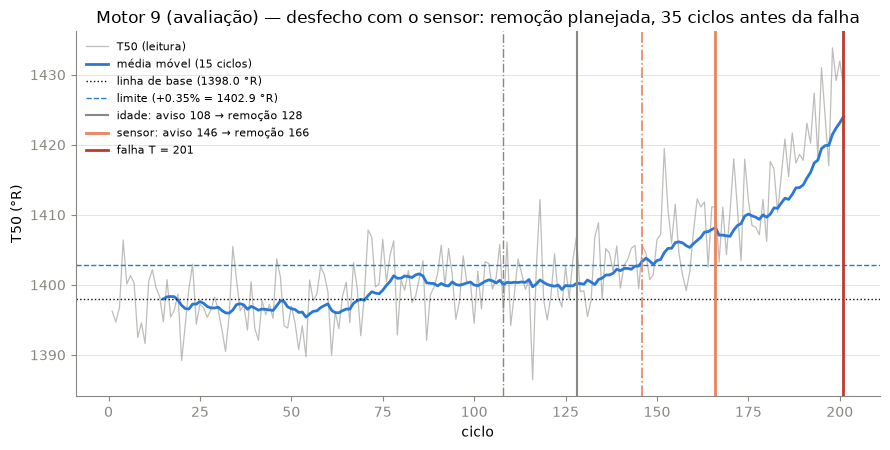

In [10]:
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)
BLUE, GRAY, INK, ORANGE, RED = "#2a78d6", "#898781", "#0b0b0b", "#ec835a", "#c0392b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.edgecolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6})

motor_ex = int((T_aval - T_aval.median()).abs().idxmin())
s = serie_t50(avaliacao[avaliacao["motor"] == motor_ex])
sr, ir = sensor_aval.loc[motor_ex], idade_aval.loc[motor_ex]
limite = s["base"].iloc[0] * (1 + melhor)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(s["ciclo"], s["t50"], color=GRAY, alpha=0.55, linewidth=0.9, label="T50 (leitura)")
ax.plot(s["ciclo"], s["media_movel"], color=BLUE, linewidth=2, label="média móvel (15 ciclos)")
ax.axhline(s["base"].iloc[0], color=INK, linestyle=":", linewidth=1, label=f"linha de base ({s['base'].iloc[0]:.1f} °R)")
ax.axhline(limite, color=BLUE, linestyle="--", linewidth=1, label=f"limite (+{melhor:.2%} = {limite:.1f} °R)")
ax.axvline(ir["aviso"], color=GRAY, linestyle="-.", linewidth=1)
ax.axvline(ir["remocao"], color=GRAY, linestyle="-", linewidth=1.5, label=f"idade: aviso {int(ir['aviso'])} → remoção {int(ir['remocao'])}")
if sr["planejada"] or pd.notna(sr["aviso"]):
    ax.axvline(sr["aviso"], color=ORANGE, linestyle="-.", linewidth=1.2)
    ax.axvline(sr["remocao"], color=ORANGE, linewidth=2, label=f"sensor: aviso {int(sr['aviso'])} → remoção {int(sr['remocao'])}")
else:
    ax.plot([], [], " ", label="sensor: SEM AVISO até a falha")
ax.axvline(sr["T"], color=RED, linewidth=2, label=f"falha T = {int(sr['T'])}")
ax.set_xlabel("ciclo")
ax.set_ylabel("T50 (°R)")
ax.set_title(f"Motor {motor_ex} (avaliação) — desfecho com o sensor: "
             f"{'remoção planejada, ' + str(int(sr['vida_desperdicada'])) + ' ciclos antes da falha' if sr['planejada'] else 'planejamento perdido'}")
ax.grid(True, axis="y")
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
fig.savefig(FIG_DIR / "motor_exemplo.png", dpi=200)
plt.show()

Visão das 30 decisões: cada linha é um motor reservado, ordenado pela vida `T`. Os marcadores
mostram onde cada regra programou a remoção; a distância até a falha (×) é a vida desperdiçada.

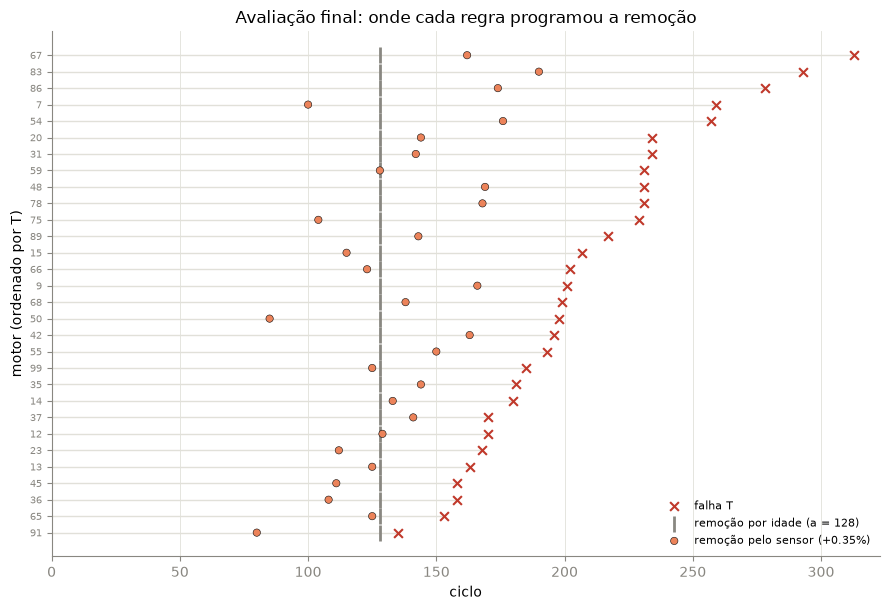

In [11]:
ordem = T_aval.sort_values().index
y = np.arange(len(ordem))
fig, ax = plt.subplots(figsize=(9, 6.2))
ax.hlines(y, 0, T_aval.loc[ordem], color="#e1e0d9", linewidth=1)
ax.scatter(T_aval.loc[ordem], y, marker="x", color=RED, s=40, label="falha T", zorder=3)
ax.scatter(idade_aval.loc[ordem, "remocao"], y, marker="|", color=GRAY, s=120, linewidths=2, label=f"remoção por idade (a = {a})", zorder=3)
cores = np.where(sensor_aval.loc[ordem, "planejada"], ORANGE, RED)
ax.scatter(sensor_aval.loc[ordem, "remocao"], y, color=cores, s=28, edgecolor=INK, linewidth=0.4,
           label=f"remoção pelo sensor (+{melhor:.2%})", zorder=4)
ax.set_yticks(y)
ax.set_yticklabels(ordem, fontsize=7)
ax.set_ylabel("motor (ordenado por T)")
ax.set_xlabel("ciclo")
ax.set_xlim(0, T_aval.max() + 10)
ax.set_title("Avaliação final: onde cada regra programou a remoção")
ax.grid(True, axis="x")
ax.legend(frameon=False, loc="lower right", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "decisoes_avaliacao.png", dpi=200)
plt.show()

## 7. Preparando a próxima pergunta (somente nos 70 motores de desenvolvimento)

A aula (slide 32) apresenta duas alternativas ao limite relativo: o **limiar estatístico**, que
compara o desvio com o ruído da linha de base, `(x̄ − μ)/(σ/√15) > k`, e a **combinação de
sensores**. Antes de propor o próximo experimento, olhamos as duas **apenas nos 70 motores de
desenvolvimento**. Os 30 reservados não são usados aqui.

**Cuidado**: esta tabela escolhe e mede nos mesmos motores. Os valores são otimistas, porque a
aula (slide 42) mostra custo 1,3 a 1,9 vez maior em motores novos do que na seleção (otimismo de
seleção). A tabela serve para **formular a hipótese**, não para concluir.

In [12]:
SENSORES_COMBINADOS = ["sensor_4", "sensor_11"]   # T50 (saída da LPT) e Ps30 (pressão estática na saída do HPC)


# Aviso no 1º ciclo >= 16 em que o desvio da média móvel supera o limite.
#   relativo: média, entre os sensores, de (média móvel / linha de base - 1) > limite
#   z: (média móvel - linha de base) / (desvio-padrão da linha de base / raiz(15)) > limite, um sensor
def avisos_generico(df: pd.DataFrame, sensores: list[str], limite: float, tipo: str = "relativo") -> pd.Series:
    avisos = {}
    for motor, g in df.groupby("motor"):
        g = g.sort_values("ciclo")
        if tipo == "relativo":
            desvio = np.mean([(g[s].rolling(JANELA).mean() / g[s].iloc[:JANELA].mean() - 1).to_numpy()
                              for s in sensores], axis=0)
        else:
            s = g[sensores[0]]
            desvio = ((s.rolling(JANELA).mean() - s.iloc[:JANELA].mean())
                      / (s.iloc[:JANELA].std(ddof=1) / np.sqrt(JANELA))).to_numpy()
        cruzou = (g["ciclo"].to_numpy() >= JANELA + 1) & (desvio > limite)
        avisos[motor] = float(g["ciclo"].to_numpy()[cruzou][0]) if cruzou.any() else np.nan
    return pd.Series(avisos, name="aviso")


assert avisos_generico(desenvolvimento, [SENSOR], melhor).equals(avisos_sensor(desenvolvimento, melhor))

variantes = [("T50, relativo", ["sensor_4"], p, "relativo") for p in PERCENTUAIS]
variantes += [("T50, limiar estatístico", ["sensor_4"], k, "z") for k in (3, 4, 5, 6)]
variantes += [("T50 + Ps30, relativo médio", SENSORES_COMBINADOS, p, "relativo") for p in (0.0025, 0.0030, 0.0035, 0.0040)]

exploracao = []
for nome, sensores, limite, tipo in variantes:
    r = desfecho(avisos_generico(desenvolvimento, sensores, limite, tipo), T_dev)
    exploracao.append({"regra": nome, "limite": f"{limite:.2%}" if tipo == "relativo" else f"k = {limite}",
                       **resumo(r), "corr(remoção, T)": np.corrcoef(r["remocao"].fillna(r["T"]), r["T"])[0, 1]})
exploracao = pd.DataFrame(exploracao).drop(columns="n")
exploracao.style.format({"vida_desperdicada_media": "{:.1f}", "custo_por_ciclo": "{:.5f}",
                         "corr(remoção, T)": "{:.2f}"}).hide(axis="index")

regra,limite,perdidos,vida_desperdicada_media,custo_por_ciclo,"corr(remoção, T)"
"T50, relativo",0.20%,0,100.9,0.00953,0.51
"T50, relativo",0.35%,0,68.3,0.00727,0.64
"T50, relativo",0.50%,1,43.6,0.01044,0.88
"T50, limiar estatístico",k = 3,0,97.7,0.00925,0.46
"T50, limiar estatístico",k = 4,0,78.8,0.00787,0.58
"T50, limiar estatístico",k = 5,1,64.1,0.01192,0.60
"T50, limiar estatístico",k = 6,1,54.1,0.01115,0.71
"T50 + Ps30, relativo médio",0.25%,0,79.2,0.00790,0.69
"T50 + Ps30, relativo médio",0.30%,0,69.1,0.00732,0.73
"T50 + Ps30, relativo médio",0.35%,0,58.5,0.00679,0.85


**Leitura**:

- **O limiar estatístico não ajuda com o T50 isolado.** Com 15 leituras ruidosas, o próprio
  desvio-padrão da linha de base é estimado com erro, e o limite passa a variar de forma
  arbitrária entre motores. Nenhum `k` supera o custo de 0,35% relativo.
- **Combinar T50 com Ps30 é mais promissor.** A média dos dois desvios relativos reduz o ruído,
  e a regra tolera limites mais altos sem perder motores, com custo menor e correlação maior
  entre remoção e vida real. Esse resultado é **in-sample** e só se sustenta se for confirmado
  em motores que não participaram da escolha. Essa é a pergunta da próxima investigação.

## 8. Conclusão

- **A regra com T50 melhorou a decisão nos 30 motores reservados, mas de forma modesta.** O
  custo por ciclo caiu de 0,00781 (idade) para 0,00737 (sensor), uma redução de **5,7%**.
  Nenhuma das duas regras perdeu planejamento, e a vida desperdiçada média caiu de 79,5 para
  71,7 ciclos.
- **O resultado ainda não é conclusivo.** No bootstrap pareado, a razão entre os custos é 0,94,
  com IC95% de [0,88; 1,02]. O intervalo inclui 1, e o sensor é mais barato em 94% das
  reamostras: é um indício favorável, não uma demonstração.
- **A personalização é parcial.** O sensor remove mais tarde que a idade em 17 dos 30 motores,
  mas o ciclo de remoção se correlaciona só moderadamente com a vida real (ver `r` acima). Alguns
  motores longos são removidos muito cedo (o motor 7 dura 259 ciclos e sai no ciclo 100),
  porque a média móvel cruza um limite pequeno por causa do ruído, e não da degradação.
- **O risco é assimétrico.** A menor folga no sensor foi de 28 ciclos, mas com `cf` = 50 basta
  **uma** remoção tardia para inverter o resultado. No desenvolvimento, 0,50% perdeu um único
  motor e ficou pior que a idade.

**Limitação**: a escolha de `p` usou uma grade de três valores em 70 motores, e a diferença entre
0,35% e 0,50% foi decidida por **um único motor**. Com 30 motores na avaliação, a incerteza do
custo por ciclo é da mesma ordem que a diferença encontrada. A referência por idade, por sua vez,
depende do **mínimo amostral** das vidas: com outro sorteio, `a` mudaria, e um motor reservado
poderia falhar antes de `a`.

**Ideia do artigo que ajudou** (Saxena et al., 2008): a seção V.A (p. 5) explica que cada
motor começa com **desgaste inicial e variação de fabricação diferentes**; isso justifica a linha
de base **por motor**, e não um limite absoluto de T50 para a frota. A seção V.B (p. 5) descreve
o **ruído de mistura** que mascara a degradação; isso explica os avisos precoces em motores longos
e motiva reduzir o ruído antes de decidir.

**Próximo experimento**: substituir o T50 isolado por **T50 combinado com Ps30**, usando a média
dos desvios relativos à linha de base de cada sensor. O limite seria escolhido por validação
cruzada interna nos 70 motores (divisão por motor, como na aula, slide 35), e a regra fixada seria
aplicada uma única vez aos mesmos 30 motores reservados. A mudança terá ajudado se, nesses 30
motores, (i) a correlação entre o ciclo de remoção e `T` subir acima de 0,58; (ii) o custo por
ciclo ficar abaixo de 0,00737, com o intervalo do bootstrap pareado contra a regra de 0,35% abaixo
de 1; e (iii) o número de planejamentos perdidos não aumentar. A exploração da §7 sugere esse
ganho, mas foi medida nos próprios motores de escolha.

### Referências

- Saxena, A.; Goebel, K.; Simon, D.; Eklund, N. *Damage Propagation Modeling for Aircraft Engine
  Run-to-Failure Simulation*. International Conference on Prognostics and Health Management
  (PHM08), 2008. Cópia local: `data/Damage Propagation Modeling.pdf`.
- Mesquita, A. C. P. *Quando remover o motor? O conjunto C-MAPSS e o planejamento de manutenção
  com antecedência logística*. TE-292, aula 7, ITA, 7/10/2026. `apresentacao/cmapss_slides.pdf`.
- Bassani, A. S. Defesa de mestrado, ITA, 5/10/2026 (`slides_defesa_ITA_Amanda.pptx`): regra de
  detecção do ponto P em T50 (slide 16) e mapa de sensores (slides 25–26).